# Estimations de la loi de Zipf par régression

La loi de Zipf dit que la taille de la ville de rang r est proportionnelle à $r^{-1/\zeta}$ avec $\zeta = 1$. On l'estime classiquement en régressant le logarithme du rang sur le logarithme de la taille : la pente est −ζ.

Cette méthode a deux défauts connus, que ce notebook illustre :

1. **Les écarts-types de la régression sont faux.** Les points ne sont pas indépendants (le rang d'une ville dépend de toutes les autres) : les résidus sont très fortement autocorrélés (statistique de Durbin-Watson proche de 0, alors qu'elle vaut 2 pour des résidus indépendants), et un R² proche de 1 est mécanique sur des données triées. Gabaix et Ibragimov (2011) donnent un écart-type corrigé, $\hat\zeta\sqrt{2/n}$.
2. **L'estimation est biaisée en petit échantillon**, et dépend du nombre n de villes retenues. La correction de Gabaix et Ibragimov consiste à régresser $\log(\text{rang} - 1/2)$.

Le notebook `maximum_vraisemblance.ipynb` présente l'alternative, qui évite ces défauts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from zipf_villes import ajuste_mco, charge_populations

DATA = Path("../data")
IMAGES = Path("../images")
com_pop, aav, msa = charge_populations(str(DATA))

# nom du jeu : (tailles, nombre de villes retenues)
jeux = {
    "communes": (com_pop["PTOT"], 100),
    "aires d'attraction": (aav["PTOT"], 150),
    "MSA": (msa["pop"], 200),
}

## Régression classique sur un échantillon

On retient, comme dans les premières analyses, les 100 plus grandes communes, les 150 plus grandes aires d'attraction et les 200 plus grandes aires métropolitaines. Le résumé de `statsmodels` montre, pour les communes, l'écart-type de la régression et la statistique de Durbin-Watson.

In [2]:
echantillon = com_pop.iloc[:100]
res = smf.ols(formula="log_rang ~ log_pop", data=echantillon).fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_rang   R-squared:                       0.981
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     5121.
Date:                Sun, 04 Oct 2026   Prob (F-statistic):           2.09e-86
Time:                        15:06:58   Log-Likelihood:                 64.826
No. Observations:                 100   AIC:                            -125.7
Df Residuals:                      98   BIC:                            -120.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     20.9653      0.242     86.459      0.000      20.484      21.447
log_pop       -1.4956      0.021    -71.558      0.000      -1.537      -1.454
==============================================================================
Omnibus:                       82.570   Durbin-Watson:                   0.519
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1643.161
Skew:                           2.200   Prob(JB):                         0.00
Kurtosis:                      22.365   Cond. No.                         222.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

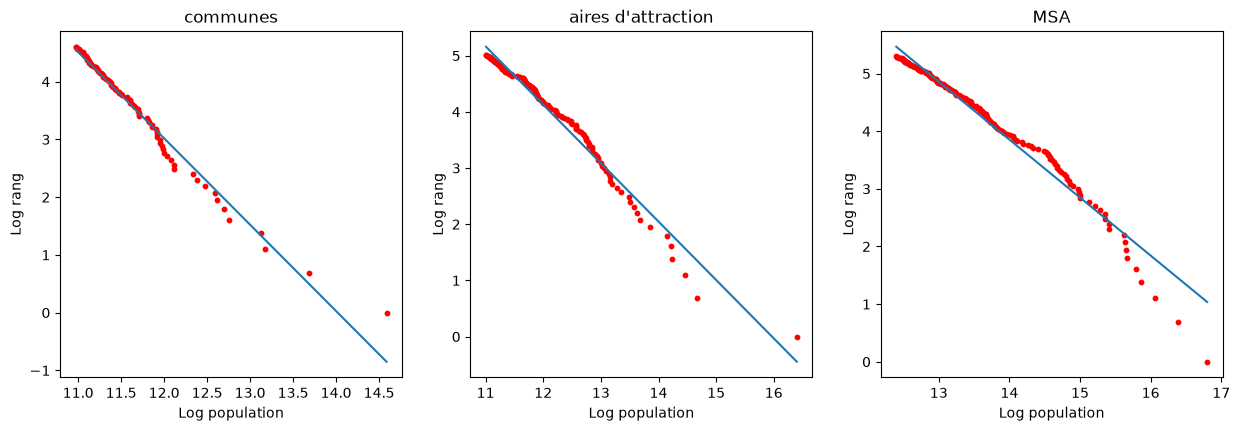

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nom, (tailles, n)) in zip(axes, jeux.items(), strict=True):
    haut = np.sort(tailles)[::-1][:n]
    x, y = np.log(haut), np.log(np.arange(1, n + 1))
    modele = sm.OLS(y, sm.add_constant(x)).fit()
    ax.scatter(x, y, c="r", s=10)
    ax.plot(x, modele.predict(sm.add_constant(x)))
    ax.set_xlabel("Log population")
    ax.set_ylabel("Log rang")
    ax.set_title(nom)
fig.savefig(IMAGES / "regressions.png", dpi=120, bbox_inches="tight")
plt.show()

## Trois variantes de la régression

Pour chaque jeu : la régression classique, la même avec la correction de Gabaix et Ibragimov, et pour chacune l'écart-type qu'affiche la régression (`erreur_mco`) comparé à l'écart-type corrigé (`erreur_gabaix`).

In [4]:
lignes = []
for nom, (tailles, n) in jeux.items():
    classique = ajuste_mco(tailles, n=n)
    corrige = ajuste_mco(tailles, n=n, decalage=0.5)
    lignes.append(
        {
            "jeu": nom,
            "n": n,
            "exposant (classique)": classique.exposant,
            "exposant (Gabaix-Ibragimov)": corrige.exposant,
            "écart-type affiché": classique.erreur_mco,
            "écart-type corrigé": corrige.erreur_gabaix,
            "R²": classique.r2,
            "Durbin-Watson": classique.durbin_watson,
        }
    )
pd.DataFrame(lignes).set_index("jeu").round(3)

,n,exposant (classique),exposant (Gabaix-Ibragimov),écart-type affiché,écart-type corrigé,R²,Durbin-Watson
jeu,,,,,,,
communes,100,1.496,1.595,0.021,0.226,0.981,0.519
aires d'attraction,150,1.040,1.087,0.013,0.126,0.977,0.477
MSA,200,1.006,1.038,0.012,0.104,0.972,0.045


L'écart-type affiché par la régression est plusieurs fois plus petit que l'écart-type corrigé (de 6 à 11 fois dans les premières analyses de ce projet) : les intervalles de confiance de la régression sont beaucoup trop étroits.

## Stabilité de l'estimation avec le nombre de villes retenues

Quand on ne garde que les n plus grandes villes, l'exposant dépend de n. On trace l'estimation pour n variant de 50 à la taille du jeu de données (au maximum 600 pour les communes, très nombreuses).

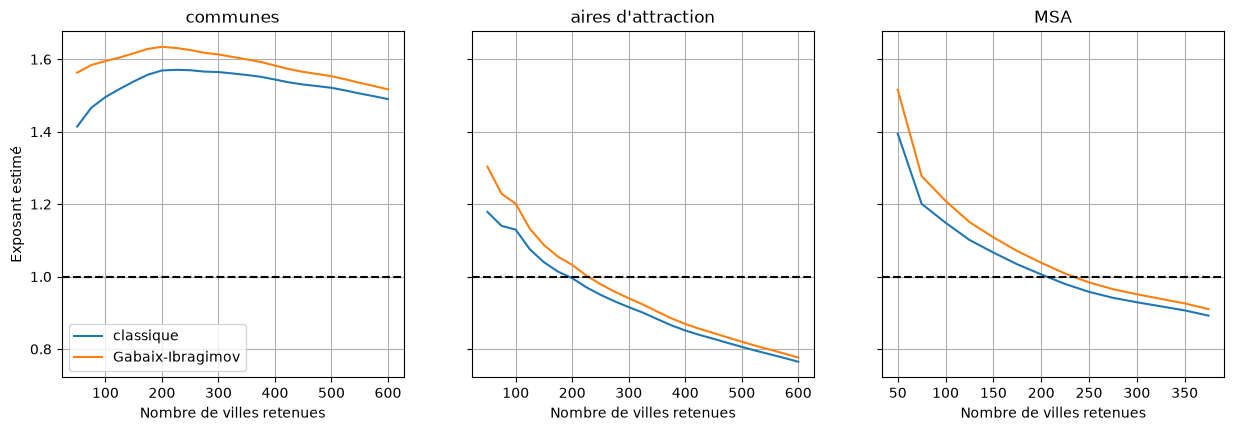

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (nom, (tailles, _)) in zip(axes, jeux.items(), strict=True):
    ns = list(range(50, min(len(tailles), 600) + 1, 25))
    ax.plot(ns, [ajuste_mco(tailles, n=n).exposant for n in ns], label="classique")
    ax.plot(
        ns,
        [ajuste_mco(tailles, n=n, decalage=0.5).exposant for n in ns],
        label="Gabaix-Ibragimov",
    )
    ax.axhline(1.0, color="k", linestyle="--")
    ax.set_title(nom)
    ax.set_xlabel("Nombre de villes retenues")
    ax.grid(True)
axes[0].set_ylabel("Exposant estimé")
axes[0].legend()
fig.savefig(IMAGES / "estim_taille.png", dpi=120, bbox_inches="tight")
plt.show()

## Histogrammes de la population

Les distributions des logarithmes des populations : le jeu complet des aires d'attraction, puis les 150 plus grandes seulement. La troncature change complètement l'allure de la distribution, et donc l'estimation.

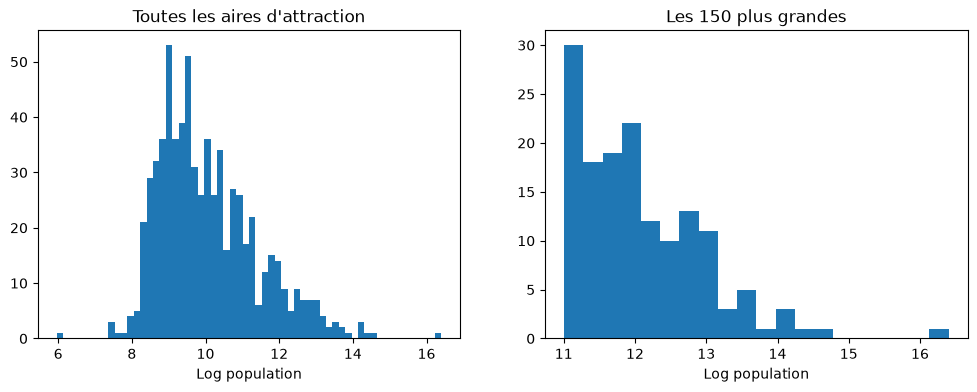

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(aav["log_pop"], bins=60)
axes[0].set_title("Toutes les aires d'attraction")
axes[1].hist(aav["log_pop"].iloc[:150], bins=20)
axes[1].set_title("Les 150 plus grandes")
for ax in axes:
    ax.set_xlabel("Log population")
fig.savefig(IMAGES / "histogrammes.png", dpi=120, bbox_inches="tight")
plt.show()

## Autres analyses

- Clémentine Cottineau, [MetaZipf](https://github.com/ClementineCttn/MetaZipf) : méta-analyse de nombreuses estimations de l'exposant de Zipf pour les villes.
- Gabaix et Ibragimov (2011), *Rank − 1/2: A simple way to improve the OLS estimation of tail exponents*, Journal of Business & Economic Statistics.